[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture1_notebook.ipynb)

# Blockchain Applications — Lecture 1: Blockchains as Data

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

This notebook reproduces the computations of Lecture 1 in the order of the slides: the proof-of-work and supply
formulas of Bitcoin, the concentration of the coin and stablecoin markets, four views of on-chain activity, a
data-quality check, and growth rates estimated on a log scale. The last part follows the appendix of the lecture.

Data (all in the `data/` folder of the course repository):
- `onchain/Crypto_<series>_20251008.csv`: daily on-chain series of eleven coins from the ETH Chronicles project,
  November 2014 to 8 October 2025;
- `snapshots/stablecoin16-...json.gz`: circulating supply of USD stablecoins from DefiLlama, to 18 September 2026;
- `snapshots/defi16-...json.gz`: total value locked in DeFi, overall and by blockchain, from DefiLlama;
- `market/`: daily closes from EODHD of Bitcoin, Ethereum, Dogecoin, Cardano, Litecoin and the iShares Bitcoin
  Trust ETF (IBIT); the lecture's samples end on 18 September 2026, the out-of-sample check on 23 October 2026.

Coins in circulation come from Coin Metrics Community Data (a free web interface, no key), read when the notebook
runs; without an internet connection the market-value, concentration and index cells say so and are skipped.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_1'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

## Setup: packages, chart style and data

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3):
    """One legend for the whole figure, outside the plot, bottom centre."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, 0.08, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Two helpers used throughout: `load_onchain` reads one on-chain file as numbers (one column per coin), and
`below` puts one legend under a figure.

In [4]:
import gzip, json, urllib.request, urllib.parse
from scipy import stats
import statsmodels.api as sm


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def below(fig, ncol=3, bottom=0.10):
    # one legend for the whole figure, under the plots
    legend_below(fig, ncol=ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))


tx, fee, val = load_onchain('transaction'), load_onchain('transactionfee'), load_onchain('transactionvalue')
hr, dif, mc, tw = load_onchain('hashrate'), load_onchain('miningdifi'), load_onchain('Mktcap'), load_onchain('tweets')
print('Coins in the on-chain files:', ', '.join(tx.columns))
print(f'Sample: {tx.index.min():%d %B %Y} to {tx.index.max():%d %B %Y}, {len(tx):,} daily rows')

Coins in the on-chain files: BTC, ETH, DOGE, ETC, XRP, LTC, BCH, ZEC, BSV, DASH, XMR
Sample: 28 November 2014 to 08 October 2025, 3,968 daily rows


## 1. What a Blockchain Records

### 1.1 Proof of work in numbers

A Bitcoin block is valid if the hash of its header together with a number (the *nonce*) is below a target $T$.
The hash $H$ behaves like a uniform draw from $\{0, \dots, 2^{256}-1\}$, so one try succeeds with probability
$p = T/2^{256}$ and the number of tries until success is geometric:

$$\mathrm{E}[\text{tries}] = \frac{1}{p} = \frac{2^{256}}{T} = D \cdot 2^{32}, \qquad D = \frac{T_{\max}}{T},\ T_{\max} \approx 2^{224}.$$

$D$ is the **difficulty**, published in every block. Because the protocol targets one block every 600 seconds, the
difficulty implies the network **hash rate** (hashes per second):

$$\hat H = \frac{D \cdot 2^{32}}{600}.$$

The cell below applies the formula to the last difficulty in the data and compares it with the hash rate reported
in the hash-rate file. One exahash per second (EH/s) is $10^{18}$ hashes per second.

In [5]:
D = dif['BTC'].dropna()
H_hat = D.iloc[-1] * 2 ** 32 / 600
print(f'Date of the last difficulty value:          {D.index[-1]:%d %B %Y}')
print(f'Bitcoin difficulty D:                       {D.iloc[-1]:.4g}')
print(f'2^32:                                       {2 ** 32:.4g}')
print(f'Implied hash rate D x 2^32 / 600:           {H_hat:.3g} hashes per second = {H_hat / 1e18:,.0f} EH/s')
print(f'Hash rate reported in the file, same day:   {hr["BTC"].dropna().iloc[-1] / 1e18:,.0f} EH/s')

Date of the last difficulty value:          08 October 2025
Bitcoin difficulty D:                       1.508e+14
2^32:                                       4.295e+09
Implied hash rate D x 2^32 / 600:           1.08e+21 hashes per second = 1,080 EH/s
Hash rate reported in the file, same day:   1,079 EH/s


### 1.2 The supply rule

The block subsidy at block height $h$ is $s(h) = 50 \cdot 2^{-\lfloor h/210\,000 \rfloor}$ BTC: it is halved every
210 000 blocks, about every four years (50, 25, 12.5, 6.25 and, since April 2024, 3.125 BTC). Total supply is a
geometric series,

$$S_\infty = 210\,000 \sum_{k=0}^{\infty} 50 \cdot 2^{-k} = 210\,000 \times 50 \times 2 = 21 \text{ million BTC}.$$

After the 2024 halving, new issuance is $3.125 \times 144 \times 365$ BTC a year (144 blocks a day), and the annual
**inflation rate** of supply is that issuance divided by the coins in circulation $S_t$. The lecture uses the
circulating supply of 18 September 2026, 20.09 million BTC. The cell also builds the supply path implied by the rule
with exactly 144 blocks a day; it is used again in the appendix.

In [6]:
S_inf = 210_000 * sum(50 * 0.5 ** k for k in range(64))
print(f'Total supply from the geometric series: {S_inf / 1e6:.6f} million BTC')

issuance = 3.125 * 144 * 365
S_t = 20.09e6                     # circulating supply on 18 September 2026 (BTC)
print(f'New BTC per year after April 2024: {issuance:,.0f}')
print(f'Inflation rate of supply: {issuance:,.0f} / {S_t / 1e6:.2f} million = {100 * issuance / S_t:.2f}% a year')

# supply path implied by the rule with exactly 144 blocks a day
days = pd.date_range('2009-01-03', '2040-12-31', freq='D')
height = np.arange(len(days)) * 144
subsidy = 50 * 0.5 ** np.floor(height / 210_000)
S_rule = pd.Series(np.minimum(np.cumsum(subsidy * 144), 21e6), index=days)
print(f"Supply by the rule on 18 September 2026: {S_rule['2026-09-18'] / 1e6:.2f} million BTC")

Total supply from the geometric series: 21.000000 million BTC
New BTC per year after April 2024: 164,250
Inflation rate of supply: 164,250 / 20.09 million = 0.82% a year
Supply by the rule on 18 September 2026: 19.98 million BTC


## 2. The Market in Numbers

### 2.1 Five coins, one dominant asset

The **market value** of coin $i$ on day $t$ is $M_{i,t} = P_{i,t} \times Q_{i,t}$, the price in USD times the coins
in circulation. Prices are EODHD daily closes; the coins in circulation are the daily current supply (`SplyCur`) from
Coin Metrics. The five coins are those with a price series and a public circulating supply: Bitcoin, Ethereum,
Dogecoin, Cardano and Litecoin. Sample: 1 January 2018 to 18 September 2026. The chart stacks the month-end market
values; the lower panel is Bitcoin's share of the five.

Market values: 3,183 days, 01 January 2018 to 18 September 2026


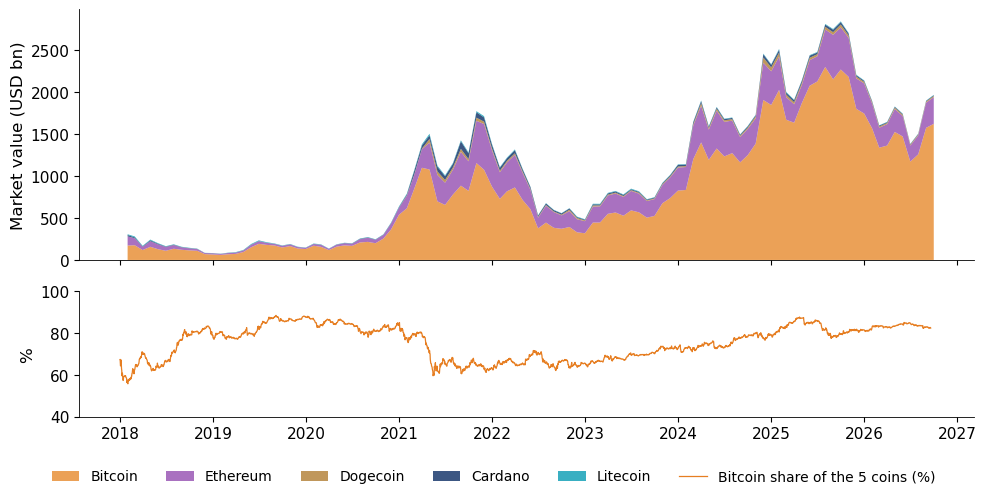

Market value of the five coins on 18 September 2026: 1,970 USD bn
Peak: 3,135 USD bn on 06 October 2025
Bitcoin: 1.63 trillion USD, a share of 82.5%
Bitcoin share since 2018: lowest 55.8% (01 Feb 2018), highest 88.5% (05 Sep 2019)


In [7]:
END = '2026-09-18'
COINS = {'BTC': ('BTC-USD.CC', 'btc', 'Bitcoin', BTC), 'ETH': ('ETH-USD.CC', 'eth', 'Ethereum', ETH),
         'DOGE': ('DOGE-USD.CC', 'doge', 'Dogecoin', GOLD), 'ADA': ('ADA-USD.CC', 'ada', 'Cardano', BLUE),
         'LTC': ('LTC-USD.CC', 'ltc', 'Litecoin', TEAL)}


def coin_supply(asset, start='2018-01-01', end=END):
    # daily current supply (coins in circulation) from Coin Metrics Community Data
    url = ('https://community-api.coinmetrics.io/v4/timeseries/asset-metrics?assets=' + asset +
           f'&metrics=SplyCur&frequency=1d&start_time={start}&end_time={end}&page_size=10000')
    rows = []
    while url:
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0 (course notebook)'})
        js = json.load(urllib.request.urlopen(req, timeout=60))
        rows += js.get('data', [])
        url = js.get('next_page_url')
    return pd.Series({pd.Timestamp(r['time'][:10]): float(r['SplyCur']) for r in rows}).sort_index()


def market_values(start='2018-01-01', end=END):
    # daily market value = close x coins in circulation, USD bn
    out = {}
    for k, (sym, cm, _, _) in COINS.items():
        px_ = daily(sym, end).loc[start:]
        out[k] = px_ * coin_supply(cm, start, end).reindex(px_.index).ffill() / 1e9
    return pd.DataFrame(out).dropna()


try:
    mv = market_values()
    print(f'Market values: {len(mv):,} days, {mv.index[0]:%d %B %Y} to {mv.index[-1]:%d %B %Y}')
except Exception as e:
    mv = None
    print(f'Coin Metrics could not be reached ({type(e).__name__}): the market-value, HHI and CRIX results below are skipped.')

if mv is not None:
    tot_mv = mv.sum(axis=1)
    share_btc = 100 * mv['BTC'] / tot_mv
    mm_ = mv.resample('ME').last()
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
    axes[0].stackplot(mm_.index, [mm_[k] for k in COINS], labels=[v[2] for v in COINS.values()],
                      colors=[v[3] for v in COINS.values()], alpha=0.85, lw=0)
    axes[0].set_ylabel('Market value (USD bn)')
    axes[1].plot(share_btc.index, share_btc.values, color=ORANGE, lw=0.9, label='Bitcoin share of the 5 coins (%)')
    axes[1].set_ylabel('%'); axes[1].set_ylim(40, 100)
    below(fig, ncol=6, bottom=0.07)
    save_fig(fig, 'ch16_market_value')
    print(f'Market value of the five coins on {mv.index[-1]:%d %B %Y}: {tot_mv.iloc[-1]:,.0f} USD bn')
    print(f'Peak: {tot_mv.max():,.0f} USD bn on {tot_mv.idxmax():%d %B %Y}')
    print(f'Bitcoin: {mv["BTC"].iloc[-1] / 1e3:.2f} trillion USD, a share of {share_btc.iloc[-1]:.1f}%')
    print(f'Bitcoin share since 2018: lowest {share_btc.min():.1f}% ({share_btc.idxmin():%d %b %Y}), '
          f'highest {share_btc.max():.1f}% ({share_btc.idxmax():%d %b %Y})')

### 2.2 How concentrated is the market?

The **Herfindahl–Hirschman index** (HHI), used by competition authorities, measures concentration:

$$\mathrm{HHI} = \sum_{i=1}^{N} w_i^2, \qquad w_i = \frac{M_i}{\sum_j M_j},$$

where $M_i$ is the market value of coin $i$, $w_i$ its value share and $N$ the number of coins. The HHI runs from
$1/N$ (equal shares) to 1 (one coin holds everything); $1/\mathrm{HHI}$ is the **effective number** of coins, the
number of equal-sized coins that would give the same HHI. The worked example of the slide uses shares of 82.5%, 15%
and 2.5%; the cell then applies the index to the five coins of Section 2.1.

In [8]:
w = np.array([0.825, 0.15, 0.025])
hhi = (w ** 2).sum()
for wi in w:
    print(f'share {wi:.3f}: squared share {wi ** 2:.4f}')
print(f'HHI = {hhi:.3f}; effective number of coins 1/HHI = {1 / hhi:.2f}')
if mv is not None:
    w5 = mv.iloc[-1] / tot_mv.iloc[-1]
    print(f'Five coins on {mv.index[-1]:%d %B %Y}: shares ' + ', '.join(f'{COINS[k][2]} {100 * v:.1f}%' for k, v in w5.items()))
    print(f'HHI = {(w5 ** 2).sum():.2f}; effective number 1/HHI = {1 / (w5 ** 2).sum():.2f}')

share 0.825: squared share 0.6806
share 0.150: squared share 0.0225
share 0.025: squared share 0.0006
HHI = 0.704; effective number of coins 1/HHI = 1.42
Five coins on 18 September 2026: shares Bitcoin 82.5%, Ethereum 16.2%, Dogecoin 0.7%, Cardano 0.4%, Litecoin 0.2%
HHI = 0.71; effective number 1/HHI = 1.42


### 2.3 A market index: CRIX

A value-weighted index of the coins, in the spirit of the CRIX (CRypto IndeX). At the end of each month the
constituents are ranked by market value; the first $k$ enter with weights proportional to their market value, the
quantities are held fixed during the next month, and the level is chained so that it does not jump at a rebalancing
(the role of the divisor, Appendix A.4). The index starts at 1 000.

How many coins? Let $\hat\sigma^2_k$ be the mean squared difference between the daily log returns of the $k$-coin index
and of the index of all five coins (the total market). The Akaike information criterion (AIC) trades fit against size:
$\mathrm{AIC}(k) = n\ln\hat\sigma^2_k + 2k$, with $n$ the number of daily returns; $\hat k$ minimises it. The
**tracking error** is the annualised standard deviation of the return difference. The chart compares the total index,
the top-2 and top-1 (Bitcoin) indices and an equally weighted index of the five coins.

                  AIC(k)  tracking error vs the total index (% a year)
constituents k                                                        
1              -32436.60                                         11.13
2              -41329.45                                          2.71
3              -44320.55                                          1.69
4              -48299.39                                          0.90
Constituents chosen by the AIC: 4


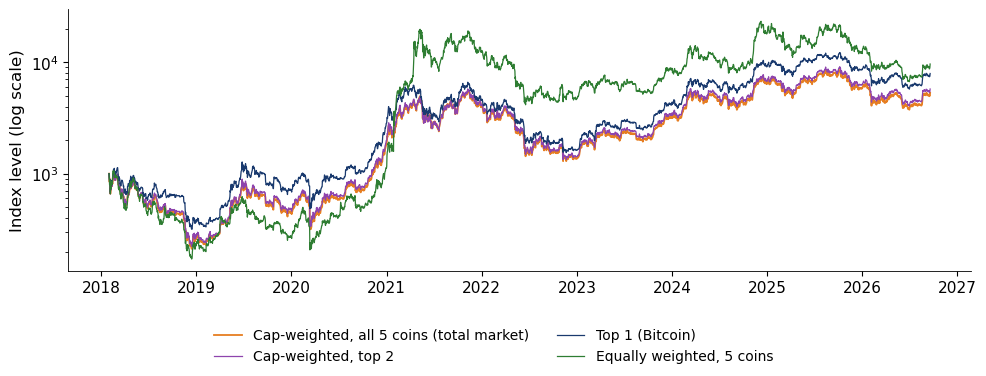

Total index from 31 January 2018: 8.6 years, compound growth 21.4% a year, volatility 65.7% a year


In [9]:
def crix_index(mv, px, k=None, weighting='cap'):
    # monthly reweighting: first k coins by market value at the previous month end; quantities fixed within the month
    months = mv.index.to_period('M')
    level = pd.Series(np.nan, index=mv.index)
    val, first = 1000.0, True
    for per in months.unique():
        idx = mv.index[months == per]
        prev = mv.loc[:idx[0] - pd.Timedelta(days=1)]
        if prev.empty:
            continue
        base = prev.iloc[-1]
        members = base.sort_values(ascending=False).index[:(k or len(base))]
        w_ = base[members] / base[members].sum() if weighting == 'cap' else pd.Series(1 / len(members), index=members)
        rel = (px.loc[idx, members] / px.loc[prev.index[-1], members]).mul(w_, axis=1).sum(axis=1)
        if first:
            level.loc[prev.index[-1]] = val
            first = False
        level.loc[idx] = val * rel
        val = level.loc[idx[-1]]
    return level.dropna()


if mv is None:
    print('Skipped: needs the Coin Metrics supply of Section 2.1.')
else:
    px = pd.concat({k: daily(v[0], END) for k, v in COINS.items()}, axis=1).reindex(mv.index)
    tot_ix = crix_index(mv, px)
    k1, k2 = crix_index(mv, px, 1), crix_index(mv, px, 2)
    ew = crix_index(mv, px, weighting='equal')
    rt = np.log(tot_ix).diff().dropna()
    rows = {}
    for k in range(1, len(COINS)):
        d = (np.log(crix_index(mv, px, k)).diff() - np.log(tot_ix).diff()).dropna()
        rows[k] = {'AIC(k)': len(rt) * np.log((d ** 2).mean()) + 2 * k,
                   'tracking error vs the total index (% a year)': 100 * d.std() * np.sqrt(365)}
    A = pd.DataFrame(rows).T.rename_axis('constituents k')
    print(A.round(2).to_string())
    print(f'Constituents chosen by the AIC: {A["AIC(k)"].idxmin()}')

    fig, ax = plt.subplots(figsize=(10, 3.8))
    for s_, lab, c, lw in [(tot_ix, 'Cap-weighted, all 5 coins (total market)', ORANGE, 1.3), (k2, 'Cap-weighted, top 2', PURPLE, 0.9),
                           (k1, 'Top 1 (Bitcoin)', BLUE, 0.9), (ew, 'Equally weighted, 5 coins', GREEN, 0.9)]:
        ax.plot(s_.index, s_.values, color=c, lw=lw, label=lab)
    ax.set_yscale('log'); ax.set_ylabel('Index level (log scale)')
    below(fig, ncol=2, bottom=0.16)
    save_fig(fig, 'ch16_crix_index')
    yrs = (tot_ix.index[-1] - tot_ix.index[0]).days / 365.25
    print(f'Total index from {tot_ix.index[0]:%d %B %Y}: {yrs:.1f} years, compound growth '
          f'{100 * ((tot_ix.iloc[-1] / 1000) ** (1 / yrs) - 1):.1f}% a year, volatility {100 * rt.std() * np.sqrt(365):.1f}% a year')

### 2.4 The rise of stablecoins

A **stablecoin** is a token designed to keep a fixed price, usually 1 USD. DefiLlama reports the circulating
supply of every USD stablecoin, valued in USD. The snapshot holds the total and one series per coin; Tether (USDT)
has DefiLlama id 1, USD Coin (USDC) id 2 and Dai (DAI) id 5. The sample ends on 18 September 2026.

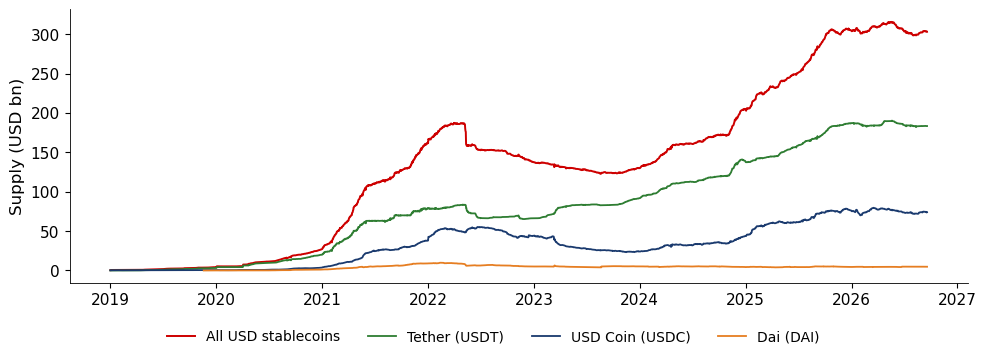

Total supply, 1 January 2020: 4.2 USD bn
Total supply, 18 September 2026: 303 USD bn, 73 times the January 2020 value
Tether (USDT): 183 USD bn, 61% of the total
USD Coin (USDC): 74 USD bn, 24% of the total
Two largest issuers together: 85% of the total
2022-2023 dip: from 187 USD bn (02 April 2022) to 123 USD bn (19 August 2023)


In [10]:
SNAP_END = '2026-09-18'


def read_snapshot(name):
    # payloads of a gzipped JSON snapshot in data/snapshots
    src = data_file('snapshots', name)
    raw = urllib.request.urlopen(src).read() if src.startswith('http') else open(src, 'rb').read()
    return json.loads(gzip.decompress(raw))['payloads']


P = read_snapshot('stablecoin16-20261021-979c073f25783889.json.gz')


def stable_series(key):
    # circulating supply in USD of one DefiLlama payload ('all' or 'id_<n>'), daily
    s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): (x.get('totalCirculatingUSD') or {}).get('peggedUSD', np.nan)
                   for x in P[key]})
    return s.sort_index().loc[:SNAP_END]


tot = stable_series('all')
usdt, usdc, dai = stable_series('id_1'), stable_series('id_2'), stable_series('id_5')

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(tot.loc['2019':] / 1e9, color=RED, lw=1.4, label='All USD stablecoins')
ax.plot(usdt.loc['2019':] / 1e9, color=GREEN, label='Tether (USDT)')
ax.plot(usdc.loc['2019':] / 1e9, color=BLUE, label='USD Coin (USDC)')
ax.plot(dai.loc['2019':] / 1e9, color=ORANGE, label='Dai (DAI)')
ax.set_ylabel('Supply (USD bn)')
below(fig, ncol=4, bottom=0.08)
save_fig(fig, 'ba_l1_stablecoin_supply')

end = tot.index[-1]
print(f"Total supply, 1 January 2020: {tot.loc['2020-01-01'] / 1e9:.1f} USD bn")
print(f'Total supply, {end:%d %B %Y}: {tot.iloc[-1] / 1e9:.0f} USD bn, '
      f"{tot.iloc[-1] / tot.loc['2020-01-01']:.0f} times the January 2020 value")
print(f'Tether (USDT): {usdt.iloc[-1] / 1e9:.0f} USD bn, {100 * usdt.iloc[-1] / tot.iloc[-1]:.0f}% of the total')
print(f'USD Coin (USDC): {usdc.iloc[-1] / 1e9:.0f} USD bn, {100 * usdc.iloc[-1] / tot.iloc[-1]:.0f}% of the total')
print(f'Two largest issuers together: {100 * (usdt.iloc[-1] + usdc.iloc[-1]) / tot.iloc[-1]:.0f}% of the total')
pk = tot.loc['2022'].idxmax(); tr = tot.loc[pk:'2023-12-31'].idxmin()
print(f'2022-2023 dip: from {tot[pk] / 1e9:.0f} USD bn ({pk:%d %B %Y}) to {tot[tr] / 1e9:.0f} USD bn ({tr:%d %B %Y})')

### 2.5 Who issues the stablecoins?

The share of each issuer is its supply divided by the total; the HHI of issuers is the sum of squared shares over
all coins in the snapshot. The sample starts in January 2019.

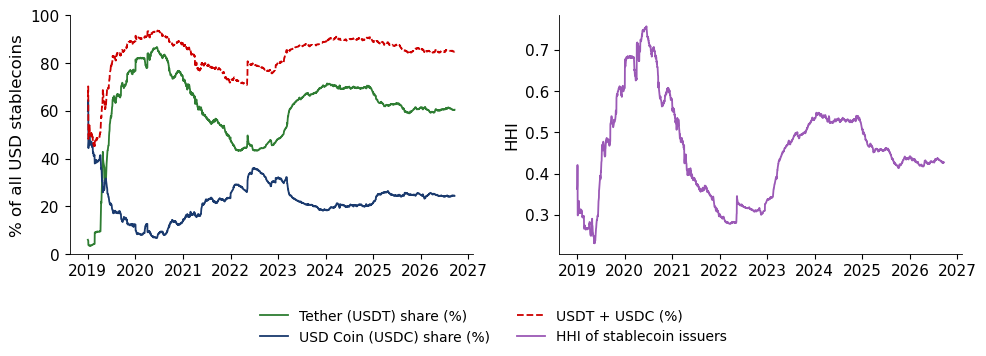

            Tether share (%)  USD Coin share (%)  HHI of issuers  total supply (USD bn)
date                                                                                   
2020-01-01            76.783              12.426           0.607                  4.171
2022-04-01            43.999              27.917           0.282                186.622
2023-08-19            67.497              20.734           0.500                122.655
2026-09-18            60.508              24.396           0.427                302.982


In [11]:
ids = [k for k in P if k.startswith('id_')]
panel = pd.DataFrame({k: stable_series(k) for k in ids}).reindex(tot.index).loc['2019-01-01':]
tot19 = tot.loc['2019-01-01':]
sh = panel.div(tot19, axis=0)
hhi_s = (sh.fillna(0) ** 2).sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(100 * sh['id_1'], color=GREEN, label='Tether (USDT) share (%)')
ax[0].plot(100 * sh['id_2'], color=BLUE, label='USD Coin (USDC) share (%)')
ax[0].plot(100 * (sh['id_1'] + sh['id_2']), color=RED, ls='--', label='USDT + USDC (%)')
ax[0].set_ylabel('% of all USD stablecoins'); ax[0].set_ylim(0, 100)
ax[1].plot(hhi_s, color=ETH, label='HHI of stablecoin issuers')
ax[1].set_ylabel('HHI')
below(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l1_stablecoin_conc')

rows = []
for d in ['2020-01-01', '2022-04-01', '2023-08-19', '2026-09-18']:
    i = sh.index.get_indexer([pd.Timestamp(d)], method='nearest')[0]
    rows.append({'date': sh.index[i].date(), 'Tether share (%)': 100 * sh['id_1'].iloc[i],
                 'USD Coin share (%)': 100 * sh['id_2'].iloc[i], 'HHI of issuers': hhi_s.iloc[i],
                 'total supply (USD bn)': tot19.iloc[i] / 1e9})
print(pd.DataFrame(rows).set_index('date').round(3).to_string())

### 2.6 DeFi: total value locked

**Total value locked** (TVL) is the value of the tokens deposited in decentralised-finance (DeFi) protocols, summed
over all blockchains (DefiLlama). The chart compares TVL with the Ether price, both at month end and set to 100 in
January 2020, on a log scale.

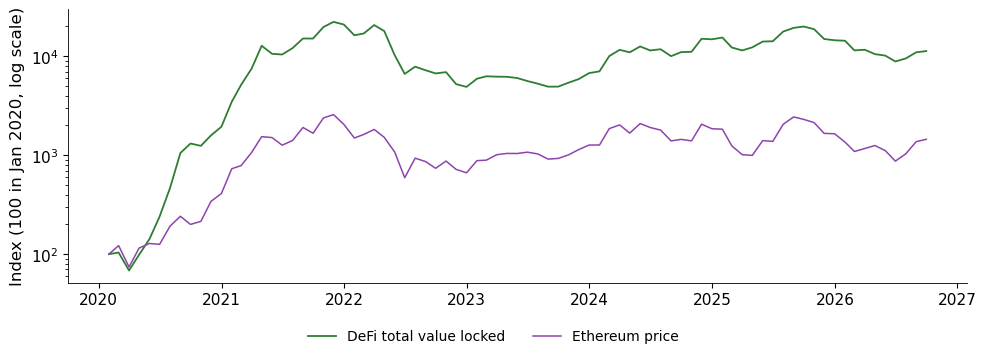

TVL on 01 January 2020: 0.6 USD bn
Peak: 177 USD bn on 09 November 2021
18 September 2026: 88 USD bn


In [12]:
DF = read_snapshot('defi16-20261016-11d0bbfc3695f65c.json.gz')


def llama_series(url):
    # daily TVL in USD bn from one DefiLlama payload
    return pd.Series({pd.Timestamp(int(x['date']), unit='s').normalize(): x['tvl'] / 1e9 for x in DF[url]}).sort_index()


tvl = llama_series('https://api.llama.fi/v2/historicalChainTvl')
tvl = tvl[tvl > 0].loc['2020-01-01':END]
eth_p = daily('ETH-USD.CC', END).loc['2020-01-01':]
mt = pd.concat([tvl.resample('ME').last(), eth_p.resample('ME').last()], axis=1, keys=['TVL', 'ETH']).dropna()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(mt.index, 100 * mt['TVL'] / mt['TVL'].iloc[0], color=GREEN, lw=1.3, label='DeFi total value locked')
ax.plot(mt.index, 100 * mt['ETH'] / mt['ETH'].iloc[0], color=PURPLE, lw=1.1, label='Ethereum price')
ax.set_yscale('log'); ax.set_ylabel('Index (100 in Jan 2020, log scale)')
below(fig, ncol=2, bottom=0.08)
save_fig(fig, 'ch16_defi_tvl')
print(f'TVL on {tvl.index[0]:%d %B %Y}: {tvl.iloc[0]:.1f} USD bn')
print(f'Peak: {tvl.max():.0f} USD bn on {tvl.idxmax():%d %B %Y}')
print(f'{tvl.index[-1]:%d %B %Y}: {tvl.iloc[-1]:.0f} USD bn')

### 2.7 January 2024: Bitcoin enters the stock exchange

A **spot ETF** is an exchange-traded fund that holds the coins themselves. On 10 January 2024 the US regulator approved
11 spot Bitcoin ETFs; trading started on 11 January. The chart sets the largest of them, the iShares Bitcoin Trust
(IBIT, adjusted close), and Bitcoin to 100 on 11 January 2024, on the days when the ETF trades, to 18 September 2026.
The annual drift of $\ln(\text{IBIT}/\text{Bitcoin})$, the slope of a linear trend in years, measures the cost of
holding Bitcoin through the fund.

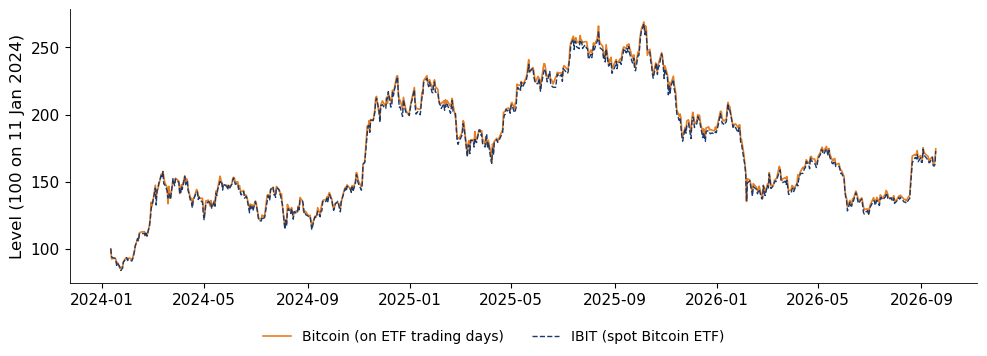

Common trading days: 674, 11 January 2024 to 18 September 2026
Level on 18 September 2026: Bitcoin 174.5, IBIT 172.8
Drift of ln(IBIT / Bitcoin): -0.24% a year


In [13]:
ib = pd.read_csv(data_file('market', 'IBIT.US.csv'), parse_dates=['date']).set_index('date')['adjusted_close'].loc[:END]
ib = ib[(ib > 0) & (ib.index.dayofweek < 5)]
pe = pd.concat([ib, daily('BTC-USD.CC', END)], axis=1, keys=['IBIT', 'BTC'], join='inner').dropna()
lvl = 100 * pe / pe.iloc[0]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(lvl.index, lvl['BTC'], color=ORANGE, lw=1.2, label='Bitcoin (on ETF trading days)')
ax.plot(lvl.index, lvl['IBIT'], color=BLUE, lw=1.0, ls='--', label='IBIT (spot Bitcoin ETF)')
ax.set_ylabel(f'Level (100 on {pe.index[0]:%d %b %Y})')
below(fig, ncol=2, bottom=0.08)
save_fig(fig, 'ch16_etf_tracking')
lr = np.log(pe['IBIT'] / pe['BTC'])
drift = np.polyfit((lr.index - lr.index[0]).days / 365.25, lr.values, 1)[0]
print(f'Common trading days: {len(pe)}, {pe.index[0]:%d %B %Y} to {pe.index[-1]:%d %B %Y}')
print(f'Level on {pe.index[-1]:%d %B %Y}: Bitcoin {lvl["BTC"].iloc[-1]:.1f}, IBIT {lvl["IBIT"].iloc[-1]:.1f}')
print(f'Drift of ln(IBIT / Bitcoin): {100 * drift:.2f}% a year')

## 3. On-Chain Activity

### 3.1 Four views of a blockchain

Four daily series describe a blockchain: **usage** (transactions per day), **fees** (the average fee per
transaction, in USD, the price of using the network), **security** (the Bitcoin hash rate, the computing power that
an attacker would have to match) and **value** (market capitalisation, price times coins in circulation). Usage and
fees are smoothed with a 30-day moving mean. All panels use log scales.

The market-value panel shows the raw series: Bitcoin's value is more than 1 000 times too small on 11 days,
27 August to 6 September 2023 (red arrow). After the chart these days are set to missing; every later
computation uses the cleaned series.

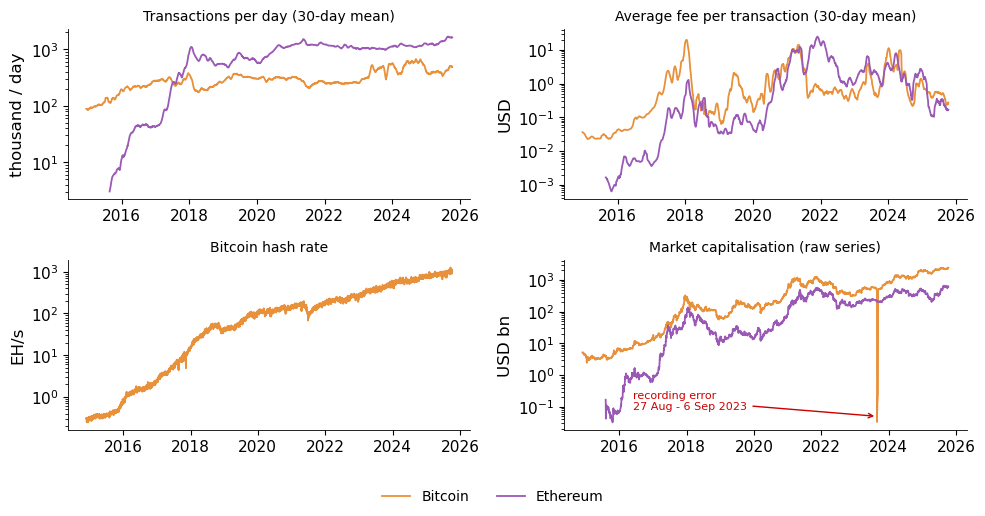

In [14]:
roll = lambda s: s.rolling(30, min_periods=20).mean()          # 30-day moving mean

fig, ax = plt.subplots(2, 2, figsize=(10, 5.2))
ax[0, 0].plot(roll(tx['BTC']) / 1e3, color=BTC, label='Bitcoin')
ax[0, 0].plot(roll(tx['ETH']) / 1e3, color=ETH, label='Ethereum')
ax[0, 0].set_ylabel('thousand / day'); ax[0, 0].set_title('Transactions per day (30-day mean)', fontsize=10)
ax[0, 1].plot(roll(fee['BTC']), color=BTC); ax[0, 1].plot(roll(fee['ETH']), color=ETH)
ax[0, 1].set_ylabel('USD'); ax[0, 1].set_title('Average fee per transaction (30-day mean)', fontsize=10)
ax[1, 0].plot(hr['BTC'] / 1e18, color=BTC)
ax[1, 0].set_ylabel('EH/s'); ax[1, 0].set_title('Bitcoin hash rate', fontsize=10)
ax[1, 1].plot(mc['BTC'] / 1e9, color=BTC); ax[1, 1].plot(mc['ETH'] / 1e9, color=ETH)
ax[1, 1].set_ylabel('USD bn'); ax[1, 1].set_title('Market capitalisation (raw series)', fontsize=10)
ax[1, 1].annotate('recording error\n27 Aug - 6 Sep 2023', xy=(pd.Timestamp('2023-08-27'), 0.05),
                  xytext=(pd.Timestamp('2016-06-01'), 0.08), fontsize=8, color=RED,
                  arrowprops=dict(arrowstyle='->', color=RED))
for a in ax.flat:
    a.set_yscale('log')
legend_below(fig, ncol=2)
save_fig(fig, 'ba_l1_onchain')

# remove the recording error for every later use
mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan

### 3.2 Reading the four panels

The cell prints the numbers quoted on the slide: the current level and the peak of each smoothed series, the growth
of the hash rate and the last market values.

In [15]:
last = tx.index.max()
print(f'Bitcoin transactions per day, mean of January 2015:     {tx.loc["2015-01", "BTC"].mean():>12,.0f}')
for c, name in [('BTC', 'Bitcoin'), ('ETH', 'Ethereum')]:
    print(f'{name} transactions per day, 30-day mean on {last:%d %b %Y}: {roll(tx[c]).dropna().iloc[-1]:>12,.0f}')
print(f'Ethereum / Bitcoin transactions (30-day means): {roll(tx["ETH"]).dropna().iloc[-1] / roll(tx["BTC"]).dropna().iloc[-1]:.1f}')
print()
for c, name in [('BTC', 'Bitcoin'), ('ETH', 'Ethereum')]:
    f = roll(fee[c])
    print(f'{name} average fee (30-day mean): peak {f.max():.2f} USD on {f.idxmax():%d %B %Y}; '
          f'last {f.dropna().iloc[-1]:.3f} USD')
print()
h = hr['BTC'].dropna()
print(f'Bitcoin hash rate: {h.iloc[0] / 1e18:.2f} EH/s on {h.index[0]:%d %B %Y}, {h.iloc[-1] / 1e18:,.0f} EH/s on '
      f'{h.index[-1]:%d %B %Y}, a factor of {h.iloc[-1] / h.iloc[0]:,.0f}')
print(f'Market value on {last:%d %B %Y}: Bitcoin {mc["BTC"].dropna().iloc[-1] / 1e9:,.0f} USD bn, '
      f'Ethereum {mc["ETH"].dropna().iloc[-1] / 1e9:,.0f} USD bn')

Bitcoin transactions per day, mean of January 2015:           93,112
Bitcoin transactions per day, 30-day mean on 08 Oct 2025:      488,729
Ethereum transactions per day, 30-day mean on 08 Oct 2025:    1,628,106
Ethereum / Bitcoin transactions (30-day means): 3.3

Bitcoin average fee (30-day mean): peak 19.81 USD on 13 January 2018; last 0.275 USD
Ethereum average fee (30-day mean): peak 24.79 USD on 25 November 2021; last 0.168 USD

Bitcoin hash rate: 0.30 EH/s on 28 November 2014, 1,079 EH/s on 08 October 2025, a factor of 3,568
Market value on 08 October 2025: Bitcoin 2,442 USD bn, Ethereum 620 USD bn


### 3.3 Does value follow activity?

Monthly means of Bitcoin's market value and transactions per day, both on log scales. The slope $b$ of the line
$\log_{10} M = a + b \log_{10} n$ is an **elasticity**: 1% more transactions goes with about $b$% more market value.
Network-value theories such as Metcalfe's law predict $b = 2$; Lecture 2 tests this formally. The colour of each
point is its year.

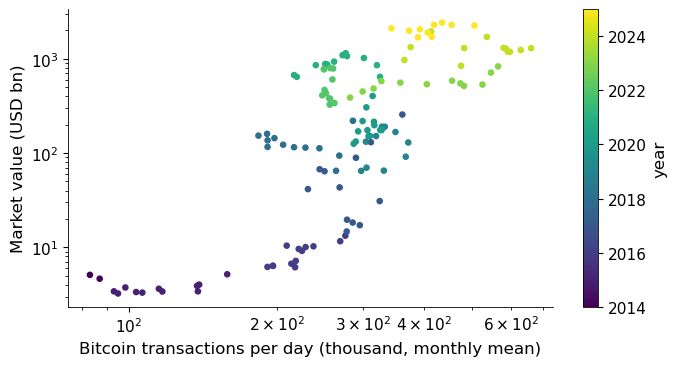

Months: 132
Correlation of log market value and log transactions: 0.76
Slope of the log-log line (elasticity): 3.59


In [16]:
m = pd.DataFrame({'tx': tx['BTC'], 'mc': mc['BTC']}).dropna().resample('ME').mean()
x, y = np.log10(m['tx']), np.log10(m['mc'])
b, a = np.polyfit(x, y, 1)

fig, axx = plt.subplots(figsize=(7, 3.8))
sc = axx.scatter(m['tx'] / 1e3, m['mc'] / 1e9, c=m.index.year, cmap='viridis', s=14)
axx.set_xscale('log'); axx.set_yscale('log')
axx.set_xlabel('Bitcoin transactions per day (thousand, monthly mean)'); axx.set_ylabel('Market value (USD bn)')
fig.colorbar(sc, ax=axx).set_label('year')
fig.tight_layout()
save_fig(fig, 'ba_l1_value_activity')

print(f'Months: {len(m)}')
print(f'Correlation of log market value and log transactions: {np.corrcoef(x, y)[0, 1]:.2f}')
print(f'Slope of the log-log line (elasticity): {b:.2f}')

## 4. Data Sources and Data Quality

### 4.1 Four real problems

Before any analysis, the on-chain files were checked. Four problems turn up; none would stop a program from
running, each would bias a result:

1. Bitcoin market value more than 1 000 times too small for 11 days (seen in the log-scale panel above);
2. the "transaction value" file is identical to the "transaction fee" file;
3. the social-media series (tweets) stops early;
4. XRP transactions have many missing values since 2020.

The cell checks each of them.

In [17]:
raw_btc = load_onchain('Mktcap')['BTC']
bad = raw_btc.loc['2023-08-27':'2023-09-06']
ratio = raw_btc.loc['2023-07-27':'2023-08-26'].median() / bad.median()
print(f'1. Bitcoin market value, 27 Aug - 6 Sep 2023: {len(bad)} days, median {bad.median() / 1e9:.2f} USD bn; '
      f'the previous month is {ratio:,.0f} times larger')
same = (fee.fillna(-1) == val.fillna(-1)).all().all()
print(f'2. "transaction value" identical to "transaction fee" in every cell: {same}')
print(f'3. Last non-missing value of the tweets series (Bitcoin): {tw["BTC"].last_valid_index():%d %B %Y}')
print(f'4. XRP transactions: {100 * tx.loc["2020":, "XRP"].isna().mean():.0f}% missing since 2020; '
      f'last value on {tx["XRP"].last_valid_index():%d %B %Y}')

1. Bitcoin market value, 27 Aug - 6 Sep 2023: 11 days, median 0.15 USD bn; the previous month is 3,880 times larger
2. "transaction value" identical to "transaction fee" in every cell: True
3. Last non-missing value of the tweets series (Bitcoin): 14 March 2023
4. XRP transactions: 32% missing since 2020; last value on 27 November 2023


### 4.2 A checklist before any analysis

The first three items of the checklist (calendar, coverage and missing values) take one line each.

In [18]:
gaps = int((tx.index.to_series().diff().dt.days > 1).sum())
print(f'Calendar: {len(tx):,} rows, dates unique: {tx.index.is_unique}, gaps of more than one day: {gaps}')
cov = pd.DataFrame({'first valid date': tx.apply(lambda s: s.first_valid_index().date()),
                    'last valid date': tx.apply(lambda s: s.last_valid_index().date()),
                    'missing since 2020 (%)': 100 * tx.loc['2020':].isna().mean()})
print('\nTransactions per day: coverage and missing values by coin')
print(cov.round(1).to_string())

Calendar: 3,968 rows, dates unique: True, gaps of more than one day: 0

Transactions per day: coverage and missing values by coin
     first valid date last valid date  missing since 2020 (%)
BTC        2014-11-28      2025-10-08                     0.0
ETH        2015-08-07      2025-10-08                     0.0
DOGE       2014-11-28      2025-10-08                     0.0
ETC        2015-08-07      2025-10-08                     0.0
XRP        2014-11-28      2023-11-27                    32.3
LTC        2014-11-28      2025-10-08                     0.0
BCH        2017-08-01      2025-10-08                     0.0
ZEC        2016-10-28      2025-10-08                     0.0
BSV        2018-11-15      2025-10-08                     0.0
DASH       2014-11-28      2025-10-08                     0.0
XMR        2014-11-28      2025-10-08                     0.0


## 5. Growth on a Log Scale

### 5.1 Why log scales?

Crypto series grow by factors of 100 or 1 000. On a log scale equal distances mean equal ratios, and a constant
growth rate is a straight line. The **log return** between two dates is $r = \ln(X_{\text{end}}/X_{\text{start}})$;
log returns add up over time. The cell checks this on the Bitcoin price in 2025: the sum of the daily log returns
equals the log return of the year.

In [19]:
p = daily('BTC-USD.CC', '2026-09-18')
p25 = p.loc['2024-12-31':'2025-12-31']
daily_lr = np.log(p25).diff().dropna()
print(f'Bitcoin, 31 Dec 2024 to 31 Dec 2025: sum of {len(daily_lr)} daily log returns = {daily_lr.sum():.4f}')
print(f'Log return of the whole period ln(P_end / P_start)          = {np.log(p25.iloc[-1] / p25.iloc[0]):.4f}')
print(f'Percentage change of the whole period                         = {100 * (p25.iloc[-1] / p25.iloc[0] - 1):.2f}%')

Bitcoin, 31 Dec 2024 to 31 Dec 2025: sum of 365 daily log returns = -0.0655
Log return of the whole period ln(P_end / P_start)          = -0.0655
Percentage change of the whole period                         = -6.34%


### 5.2 Growth as a regression: the log-linear trend

A compound annual growth rate (CAGR) uses only two dates; a trend regression uses all of them:

$$\ln X_t = a + g\,t + u_t, \qquad t \text{ in years}.$$

$g$ is the continuous growth rate and $e^{g} - 1$ the annual growth. The errors $u_t$ are strongly autocorrelated, so
standard errors are Newey–West (heteroskedasticity- and autocorrelation-consistent, HAC) with 12 lags. Data: monthly
means of Bitcoin transactions per day and of Bitcoin market value, November 2014 to October 2025. The difference of
the two growth rates is compared with its standard error, ignoring the covariance of the two estimates:
$z \approx (\hat g_2 - \hat g_1)/\sqrt{\mathrm{SE}_1^2 + \mathrm{SE}_2^2}$.

In [20]:
series = {'transactions per day': tx['BTC'], 'market value (USD million)': mc['BTC'] / 1e6}
trend, rows = {}, []
for lab, s in series.items():
    mth = s.resample('ME').mean().dropna()
    t = np.arange(len(mth)) / 12
    fit = sm.OLS(np.log(mth.values), sm.add_constant(t)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
    trend[lab] = (mth, fit)
    rows.append({'Bitcoin, monthly': lab, 'months': len(mth), 'g': fit.params[1], 'SE (Newey-West)': fit.bse[1],
                 'R2': fit.rsquared, 'annual growth exp(g)-1 (%)': 100 * (np.exp(fit.params[1]) - 1)})
T = pd.DataFrame(rows).set_index('Bitcoin, monthly')
print(T.round(3).to_string())
g1, g2 = T['g']; s1, s2 = T['SE (Newey-West)']
print(f'\nDifference of the growth rates: {g2 - g1:.2f}; z = {g2 - g1:.2f} / sqrt({s1:.3f}^2 + {s2:.3f}^2) = '
      f'{(g2 - g1) / np.sqrt(s1 ** 2 + s2 ** 2):.1f}')

                            months      g  SE (Newey-West)     R2  annual growth exp(g)-1 (%)
Bitcoin, monthly                                                                             
transactions per day           132  0.104            0.021  0.617                      10.946
market value (USD million)     132  0.586            0.055  0.884                      79.723

Difference of the growth rates: 0.48; z = 0.48 / sqrt(0.021^2 + 0.055^2) = 8.2


### 5.3 Trend lines on a log scale

Monthly means (solid) and the fitted trends (dashed). A constant growth rate is a straight line; the market value
moves around its trend in long waves.

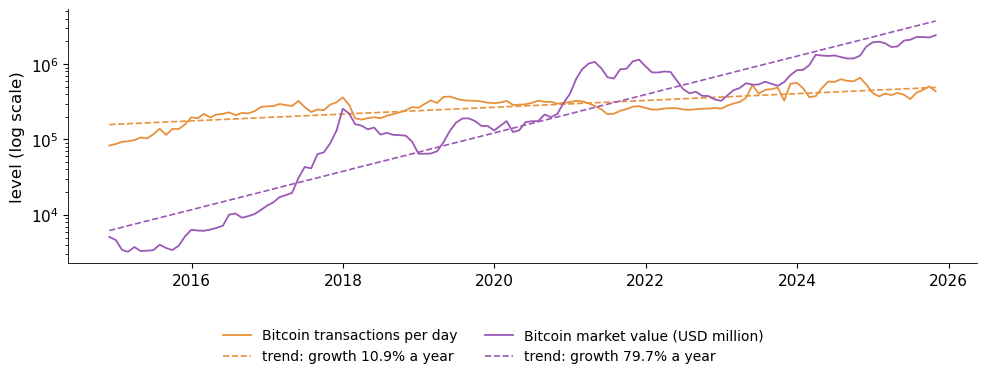

In [21]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for (lab, (mth, fit)), col in zip(trend.items(), [BTC, ETH]):
    ax.plot(mth.index, mth.values, color=col, label=f'Bitcoin {lab}')
    ax.plot(mth.index, np.exp(fit.fittedvalues), color=col, ls='--', lw=1.2,
            label=f'trend: growth {100 * (np.exp(fit.params[1]) - 1):.1f}% a year')
ax.set_yscale('log'); ax.set_ylabel('level (log scale)')
below(fig, ncol=2, bottom=0.18)
save_fig(fig, 'ba_l1_trend')

### 5.4 Out of sample: the trend one year later

The market-value trend, estimated on data to October 2025, is extended month by month from November 2025. A naive
95% band adds $\pm 1.96$ residual standard deviations in logs, as if the residuals were independent and identically
distributed (iid). The realised market value is the EODHD daily close times the circulating supply, averaged by
month. Supply follows the protocol rule at the block rate actually observed since 2009: the circulating supply of
24 October 2026, 20 102 728 BTC, implies a block height of $840\,000 + (20\,102\,728 - 19\,687\,500)/3.125$ and
hence a number of blocks per day. Prices run to 23 October 2026, so the October 2026 mean covers 1–23 October.

The first-order autocorrelation of the residuals (the AR(1) coefficient) measures how persistent the deviations
from the trend are.

Implied block height: 972,873; realised blocks per day since 3 January 2009: 149.6
          trend forecast (USD bn)  naive 95% band, low  naive 95% band, high  realised (USD bn)  realised / forecast
Nov 2025                  3918.38              1033.94              14849.75            1920.22                 0.49
Dec 2025                  4114.56              1085.70              15593.24            1775.00                 0.43
Jan 2026                  4320.57              1140.06              16373.95            1807.00                 0.42
Feb 2026                  4536.88              1197.14              17193.74            1375.67                 0.30
Mar 2026                  4764.03              1257.08              18054.58            1389.74                 0.29
Apr 2026                  5002.55              1320.02              18958.52            1476.05                 0.30
May 2026                  5253.02              1386.11              19907.72            1561.93   

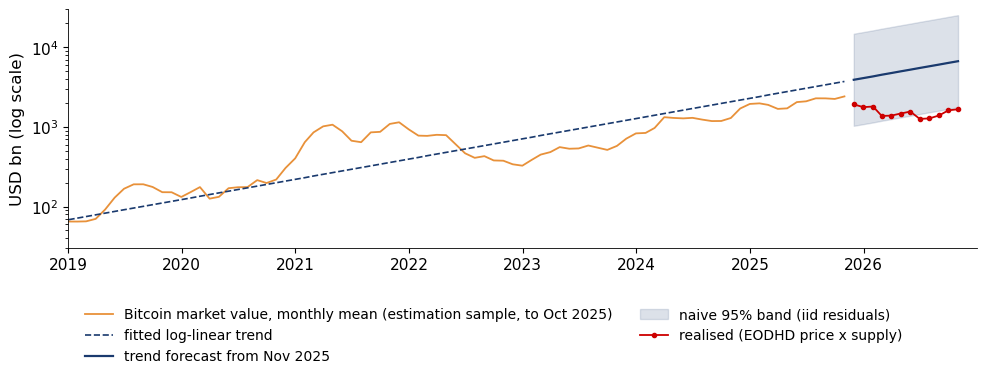

In [22]:
mth, fit = trend['market value (USD million)']
sres = np.std(fit.resid, ddof=2)                        # residual standard deviation, in logs
actual_supply = 20_102_728                              # circulating BTC on 24 October 2026
height_now = 840_000 + (actual_supply - 19_687_500) / 3.125
bpd = height_now / (pd.Timestamp('2026-10-24') - pd.Timestamp('2009-01-03')).days
print(f'Implied block height: {height_now:,.0f}; realised blocks per day since 3 January 2009: {bpd:.1f}')

S_real = pd.Series(np.minimum(np.cumsum(50 * 0.5 ** np.floor(np.arange(len(days)) * bpd / 210_000) * bpd), 21e6),
                   index=days)
p_oos = daily('BTC-USD.CC', '2026-10-23')
real = (p_oos * S_real.reindex(p_oos.index)).resample('ME').mean()
fut = pd.date_range('2025-11-30', '2026-10-31', freq='ME')
tf = (len(mth) - 1) / 12 + np.arange(1, len(fut) + 1) / 12
pred = np.exp(fit.params[0] + fit.params[1] * tf) * 1e6          # back to USD
lo, hi = pred * np.exp(-1.96 * sres), pred * np.exp(1.96 * sres)
oos = pd.DataFrame({'trend forecast (USD bn)': pred / 1e9, 'naive 95% band, low': lo / 1e9,
                    'naive 95% band, high': hi / 1e9, 'realised (USD bn)': real.reindex(fut).values / 1e9},
                   index=fut.strftime('%b %Y'))
oos['realised / forecast'] = oos['realised (USD bn)'] / oos['trend forecast (USD bn)']
print(oos.round(2).to_string())
print(f'\nResidual standard deviation (logs): {sres:.3f}')
print(f'AR(1) coefficient of the trend residuals: {sm.tsa.acf(fit.resid, nlags=1)[1]:.2f}')

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(mth.index, mth / 1e3, color=BTC, label='Bitcoin market value, monthly mean (estimation sample, to Oct 2025)')
ax.plot(mth.index, np.exp(fit.fittedvalues) / 1e3, color=BLUE, ls='--', lw=1.2, label='fitted log-linear trend')
ax.plot(fut, pred / 1e9, color=BLUE, lw=1.6, label='trend forecast from Nov 2025')
ax.fill_between(fut, lo / 1e9, hi / 1e9, color=BLUE, alpha=0.15, label='naive 95% band (iid residuals)')
ax.plot(fut, oos['realised (USD bn)'].values, color=RED, marker='o', ms=3, label='realised (EODHD price x supply)')
ax.set_yscale('log'); ax.set_ylabel('USD bn (log scale)'); ax.set_ylim(30, 3e4)
ax.set_xlim(pd.Timestamp('2019-01-01'), pd.Timestamp('2026-12-31'))
below(fig, ncol=2, bottom=0.22)
save_fig(fig, 'ba_oos_trend')

## Appendix: Further Material

### A.1 A miner with 1% of the hash rate

Each block is won by a miner with probability equal to its share $s$ of the hash rate, independently of the past.
With 144 blocks a day, the number of blocks $N$ a miner wins in a day is approximately Poisson with mean
$\lambda = 144\,s$:

$$P(N = k) = e^{-\lambda}\frac{\lambda^k}{k!}.$$

In [23]:
lam = 144 * 0.01
print(f'Mean number of blocks a day for a 1% miner: lambda = {lam:.2f}')
print(f'Probability of no block in a day: P(N = 0) = {stats.poisson.pmf(0, lam):.3f}')
print(f'Probability of at least three blocks: P(N >= 3) = {stats.poisson.sf(2, lam):.3f}')

Mean number of blocks a day for a 1% miner: lambda = 1.44
Probability of no block in a day: P(N = 0) = 0.237
Probability of at least three blocks: P(N >= 3) = 0.176


### A.2 Checking the hash-rate formula on the data

The reported hash rate is compared with $D \cdot 2^{32}/600$ computed from the published difficulty, month by month.
A ratio above 1 means blocks arrived slightly faster than every 600 seconds.

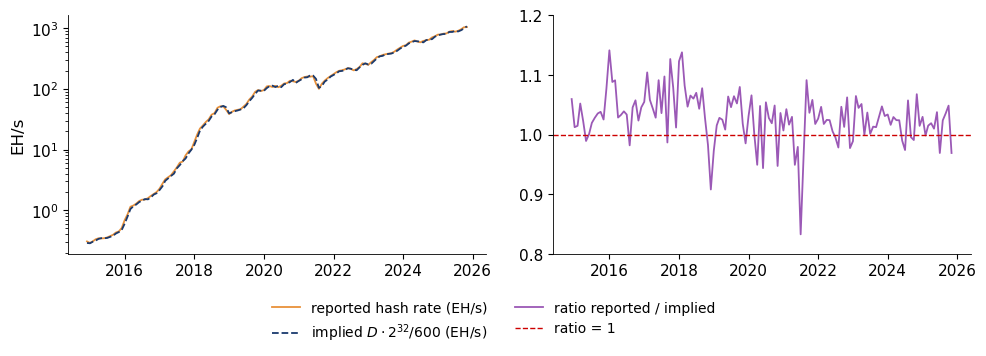

Ratio reported / implied, monthly, Nov 2014 - Oct 2025: mean 1.029, standard deviation 0.042, minimum 0.83, maximum 1.14


In [24]:
implied = dif['BTC'] * 2 ** 32 / 600
mh = pd.DataFrame({'rep': hr['BTC'], 'imp': implied}).resample('ME').mean().dropna()
rr = mh['rep'] / mh['imp']

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(mh.index, mh['rep'] / 1e18, color=BTC, label='reported hash rate (EH/s)')
ax[0].plot(mh.index, mh['imp'] / 1e18, color=BLUE, ls='--', label=r'implied $D\cdot 2^{32}/600$ (EH/s)')
ax[0].set_yscale('log'); ax[0].set_ylabel('EH/s')
ax[1].plot(rr.index, rr, color=ETH, label='ratio reported / implied')
ax[1].axhline(1, color=RED, ls='--', lw=1, label='ratio = 1')
ax[1].set_ylim(0.8, 1.2)
below(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l1_hashrate_check')
print(f'Ratio reported / implied, monthly, {mh.index[0]:%b %Y} - {mh.index[-1]:%b %Y}: mean {rr.mean():.3f}, '
      f'standard deviation {rr.std():.3f}, minimum {rr.min():.2f}, maximum {rr.max():.2f}')

### A.3 Checking the supply rule a year later

The rule-based path assumes exactly 144 blocks a day. On 24 October 2026 the circulating supply was 20 102 728 BTC.
Inside the fourth subsidy epoch (3.125 BTC per block since height 840 000, when 19 687 500 BTC existed) the supply
gives the block height, and the height gives the realised block rate. The next halving comes at height 1 050 000.

In [25]:
pred_rule = S_rule['2026-10-24']
print(f'Supply by the rule (144 blocks a day) on 24 October 2026: {pred_rule:,.0f} BTC')
print(f'Circulating supply on 24 October 2026: {actual_supply:,} BTC, {actual_supply - pred_rule:,.0f} BTC '
      f'({100 * (actual_supply / pred_rule - 1):.2f}%) more')
ndays = (pd.Timestamp('2026-10-24') - pd.Timestamp('2009-01-03')).days
print(f'Implied block height: {height_now:,.0f}; days since 3 January 2009: {ndays:,}')
print(f'Realised blocks per day: {bpd:.1f}, {100 * (bpd / 144 - 1):.1f}% more than the target of 144')
nxt = pd.Timestamp('2026-10-24') + pd.Timedelta(days=(1_050_000 - height_now) / 144)
print(f'Next halving (height 1 050 000) at 144 blocks a day: about {nxt:%d %B %Y}')

Supply by the rule (144 blocks a day) on 24 October 2026: 19,992,600 BTC
Circulating supply on 24 October 2026: 20,102,728 BTC, 110,128 BTC (0.55%) more
Implied block height: 972,873; days since 3 January 2009: 6,503
Realised blocks per day: 149.6, 3.9% more than the target of 144
Next halving (height 1 050 000) at 144 blocks a day: about 11 April 2028


### A.4 Building a market-value index: the divisor

A value-weighted index of $k$ coins divides total market value by a **divisor** $D_t$:

$$I_t = \frac{\sum_{i=1}^{k} P_{i,t}\,Q_{i,t}}{D_t}, \qquad
D_{t^*}^{\text{new}} = D_{t^*}^{\text{old}} \cdot \frac{\sum_{i \in \text{new}} P_{i,t^*}Q_{i,t^*}}{\sum_{i \in \text{old}} P_{i,t^*}Q_{i,t^*}}.$$

At a rebalancing date $t^*$ the divisor changes so that the index does not jump. The CRIX index chooses $k$ with an
Akaike information criterion (AIC)-type rule, $\hat k = \arg\min_k\, n\ln\hat\sigma^2_k + 2k$, where $\hat\sigma^2_k$ is
the variance of the difference between the $k$-coin index return and the total-market return. The worked example:
coins A and B worth 800 and 200 (USD bn), divisor 1; coin C worth 100 enters; the next day A, B and C are worth
820, 190 and 110.

In [26]:
D_old = 1.0
D_new = D_old * (800 + 200 + 100) / (800 + 200)
print(f'Divisor after C enters: {D_new:.2f}; index on the rebalancing day: {(800 + 200 + 100) / D_new:,.1f}')
I1 = (820 + 190 + 110) / D_new
print(f'Index on the next day: {I1:,.1f}, a return of {100 * (I1 / 1000 - 1):+.2f}%')
print(f'Without updating the divisor, the rebalancing day would show {100 * (1100 / 1000 - 1):+.0f}%')

Divisor after C enters: 1.10; index on the rebalancing day: 1,000.0
Index on the next day: 1,018.2, a return of +1.82%
Without updating the divisor, the rebalancing day would show +10%


### A.5 How much of TVL is just the Ether price?

Monthly regression of log changes, with Newey–West (HAC) standard errors (3 lags):

$$\Delta\ln \mathrm{TVL}_t = a + b\,\Delta\ln P^{\mathrm{ETH}}_t + u_t.$$

$b$ is the elasticity of TVL to the Ether price. Because $\mathrm{TVL}_t = \sum_j P_{j,t} N_{j,t}$, prices times
token quantities deposited, part of every move in TVL is a price effect, not new deposits. Month-end values of
Section 2.6, January 2020 to September 2026.

In [27]:
dl = np.log(mt).diff().dropna()
reg = sm.OLS(dl['TVL'], sm.add_constant(dl['ETH'])).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
b_, se_ = reg.params['ETH'], reg.bse['ETH']
print(f'Months: {len(dl)}')
print(f'Elasticity b = {b_:.2f} (Newey-West SE {se_:.2f}); t = {b_ / se_:.1f}; R2 = {reg.rsquared:.2f}')

Months: 80
Elasticity b = 0.79 (Newey-West SE 0.07); t = 12.0; R2 = 0.62


### A.6 TVL without new deposits

Total value locked (TVL) is the value of tokens deposited in decentralised-finance (DeFi) protocols:
$\mathrm{TVL}_t = \sum_j P_{j,t} N_{j,t}$, prices times quantities deposited. A protocol holds 100 million USD, 60% in
Ether and 40% in stablecoins; Ether rises by 50% and nobody deposits or withdraws. Across the market, the lecture
estimates an elasticity of TVL to the Ether price of $\hat b = 0.79$ (DefiLlama data, monthly, 80 months).

In [28]:
tvl0, tvl1 = 60 + 40, 60 * 1.5 + 40
print(f'TVL before: {tvl0} million USD; after: {tvl1:.0f} million USD, a change of {100 * (tvl1 / tvl0 - 1):+.0f}%')
print(f'Elasticity of this protocol to the Ether price: {(tvl1 / tvl0 - 1) / 0.5:.1f} (the Ether share of deposits)')
print(f'Fixed-price TVL (quantities at the old prices): {tvl0} million USD, unchanged')

TVL before: 100 million USD; after: 130 million USD, a change of +30%
Elasticity of this protocol to the Ether price: 0.6 (the Ether share of deposits)
Fixed-price TVL (quantities at the old prices): 100 million USD, unchanged


### A.7 A robust outlier rule

The mean and the standard deviation are themselves distorted by outliers. A robust z-score uses the median and the
**median absolute deviation** (MAD) on a centred 31-day window:

$$z_t = \frac{x_t - \mathrm{med}_t}{1.4826\,\mathrm{MAD}_t}, \qquad \mathrm{MAD}_t = \mathrm{med}\,\big|x_s - \mathrm{med}_t\big|.$$

$x_t$ is the log market value of Bitcoin (raw series, with the 11 bad days); 1.4826 makes $1.4826\,\mathrm{MAD}$ equal
to the standard deviation for Normal data. Days where the MAD is zero (the series did not change for weeks, a sign of stale data) have no finite $z_t$ and are left out.

Days with a finite robust z-score: 3,958; days with MAD = 0 (left out): 10
The 11 bad days: |z| between 539 and 689
Largest |z| on any other day: 48.6 (11 May 2017)
Days flagged by |z| > 100: 11; days flagged by the usual |z| > 3: 208


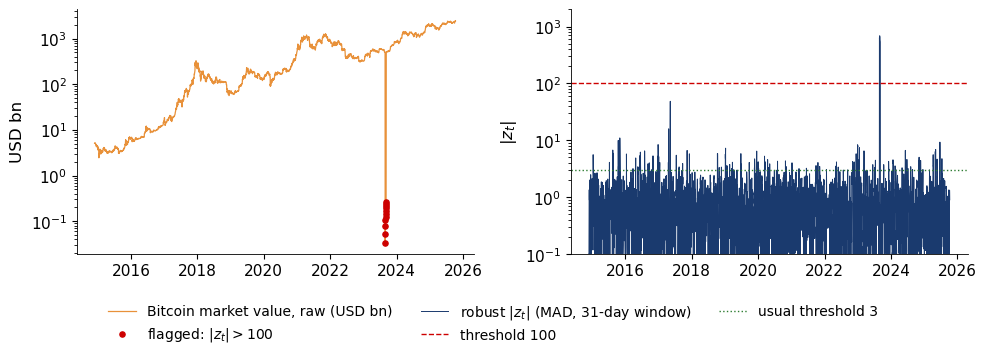

In [29]:
lx = np.log(raw_btc)
med = lx.rolling(31, center=True, min_periods=15).median()
mad = (lx - med).abs().rolling(31, center=True, min_periods=15).median()
z = (lx - med) / (1.4826 * mad)
n_mad0 = int((mad == 0).sum())
z = z[np.isfinite(z)]
flag = z.abs() > 100
bad_days = z.loc['2023-08-27':'2023-09-06'].abs()
other = z.drop(bad_days.index).abs()
print(f'Days with a finite robust z-score: {len(z):,}; days with MAD = 0 (left out): {n_mad0}')
print(f'The 11 bad days: |z| between {bad_days.min():.0f} and {bad_days.max():.0f}')
print(f'Largest |z| on any other day: {other.max():.1f} ({other.idxmax():%d %B %Y})')
print(f'Days flagged by |z| > 100: {int(flag.sum())}; days flagged by the usual |z| > 3: {int((z.abs() > 3).sum())}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(raw_btc.index, raw_btc / 1e9, color=BTC, lw=0.9, label='Bitcoin market value, raw (USD bn)')
fl = flag[flag].index
ax[0].scatter(fl, raw_btc[fl] / 1e9, color=RED, s=14, zorder=5, label=r'flagged: $|z_t| > 100$')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD bn')
ax[1].plot(z.index, z.abs().clip(lower=0.1), color=BLUE, lw=0.7, label=r'robust $|z_t|$ (MAD, 31-day window)')
ax[1].axhline(100, color=RED, ls='--', lw=1, label='threshold 100')
ax[1].axhline(3, color=GREEN, ls=':', lw=1, label='usual threshold 3')
ax[1].set_yscale('log'); ax[1].set_ylim(0.1, 2000); ax[1].set_ylabel(r'$|z_t|$')
below(fig, ncol=3, bottom=0.16)
save_fig(fig, 'ba_l1_mad')

### A.8 The supply schedule

The supply path of the rule (144 blocks a day) and its annual growth, $100\,(S_t - S_{t-365})/S_{t-365}$, on a log
scale. Dotted green lines mark the four halvings.

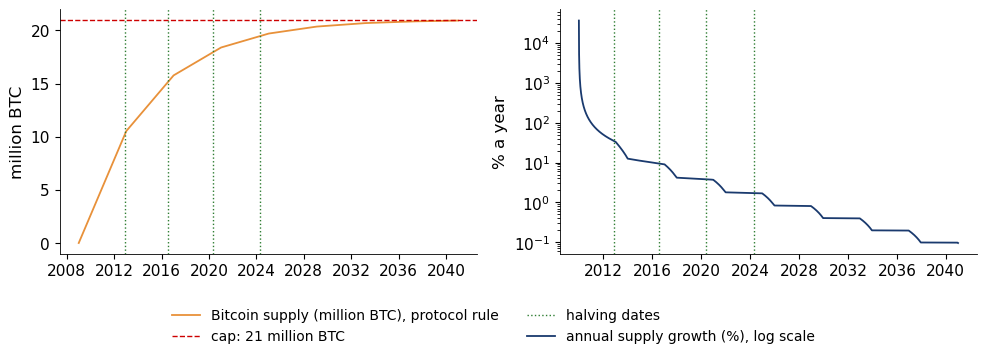

             supply by the rule (million BTC)  annual supply growth (%)
1 Jan 2013                             10.508                    33.288
1 Jan 2017                             15.761                     9.041
1 Jan 2021                             18.384                     3.669
1 Jan 2025                             19.695                     1.675
18 Sep 2026                            19.976                     0.829
1 Jan 2032                             20.596                     0.400

Year in which supply reaches 99% of the cap: 2035


In [30]:
infl = 100 * S_rule.diff(365) / S_rule.shift(365)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(S_rule.index, S_rule / 1e6, color=BTC, label='Bitcoin supply (million BTC), protocol rule')
ax[0].axhline(21, color=RED, ls='--', lw=1, label='cap: 21 million BTC')
ax[0].set_ylabel('million BTC')
ax[1].plot(infl.index, infl, color=BLUE, label='annual supply growth (%), log scale')
ax[1].set_yscale('log'); ax[1].set_ylabel('% a year')
for i, d in enumerate(['2012-11-28', '2016-07-09', '2020-05-11', '2024-04-20']):
    for a in ax:
        a.axvline(pd.Timestamp(d), color=GREEN, ls=':', lw=1, label='halving dates' if (i == 0 and a is ax[0]) else None)
below(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l1_supply_schedule')

tab = pd.DataFrame({'supply by the rule (million BTC)': [S_rule[d] / 1e6 for d in
                     ['2013-01-01', '2017-01-01', '2021-01-01', '2025-01-01', '2026-09-18', '2032-01-01']],
                    'annual supply growth (%)': [infl[d] for d in
                     ['2013-01-01', '2017-01-01', '2021-01-01', '2025-01-01', '2026-09-18', '2032-01-01']]},
                   index=['1 Jan 2013', '1 Jan 2017', '1 Jan 2021', '1 Jan 2025', '18 Sep 2026', '1 Jan 2032'])
print(tab.round(3).to_string())
print(f'\nYear in which supply reaches 99% of the cap: {S_rule[S_rule >= 0.99 * 21e6].index[0].year}')

### A.9 Concentration through time

Monthly market-value shares of the eleven coins of the on-chain files (the 11 bad days removed) and the HHI with its
effective number of coins.

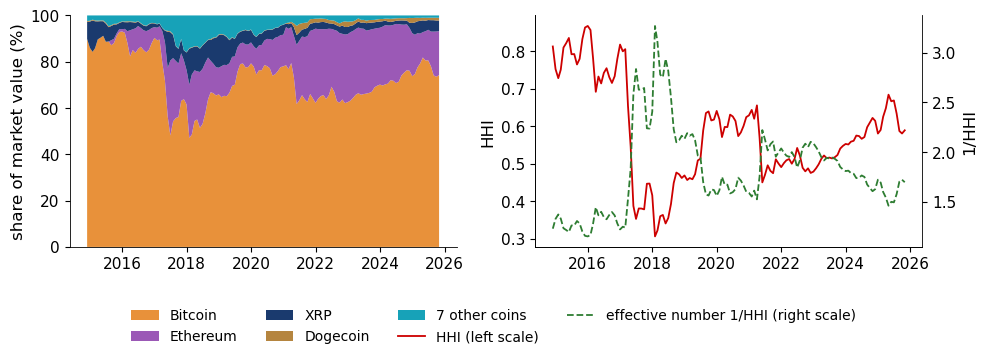

           HHI  effective number  Bitcoin share (%)
month                                              
2015-12  0.868             1.152             93.085
2018-01  0.306             3.267             47.128
2021-05  0.450             2.221             61.729
2025-09  0.581             1.722             73.498

HHI maximum 0.868 (December 2015); minimum 0.306 (January 2018)


In [31]:
mm = mc.resample('ME').mean()
wts = mm.div(mm.sum(axis=1, min_count=1), axis=0)
hhi_c = (wts ** 2).sum(axis=1, min_count=1)
top = ['BTC', 'ETH', 'XRP', 'DOGE']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].stackplot(wts.index, [wts[c].fillna(0) * 100 for c in top] + [wts.drop(columns=top).sum(axis=1) * 100],
                colors=[BTC, ETH, BLUE, GOLD, TEAL], labels=['Bitcoin', 'Ethereum', 'XRP', 'Dogecoin', '7 other coins'])
ax[0].set_ylabel('share of market value (%)'); ax[0].set_ylim(0, 100)
ax[1].plot(hhi_c.index, hhi_c, color=RED, label='HHI (left scale)')
ax2 = ax[1].twinx(); ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(True)
ax2.plot(hhi_c.index, 1 / hhi_c, color=GREEN, ls='--', label='effective number 1/HHI (right scale)')
ax[1].set_ylabel('HHI'); ax2.set_ylabel('1/HHI')
below(fig, ncol=4, bottom=0.18)
save_fig(fig, 'ba_l1_hhi_coins')

rows = [{'month': d, 'HHI': hhi_c.loc[d].iloc[0], 'effective number': 1 / hhi_c.loc[d].iloc[0],
         'Bitcoin share (%)': 100 * wts.loc[d, 'BTC'].iloc[0]} for d in ['2015-12', '2018-01', '2021-05', '2025-09']]
print(pd.DataFrame(rows).set_index('month').round(3).to_string())
print(f'\nHHI maximum {hhi_c.max():.3f} ({hhi_c.idxmax():%B %Y}); minimum {hhi_c.min():.3f} ({hhi_c.idxmin():%B %Y})')

### A.10 Where the value is locked

TVL by blockchain on 18 September 2026: the ten largest of the fifteen chains with the highest TVL when the snapshot
was taken (16 October 2026), each at its last value up to 18 September. Base and Arbitrum are **layer-2** networks,
cheaper chains that settle on Ethereum.

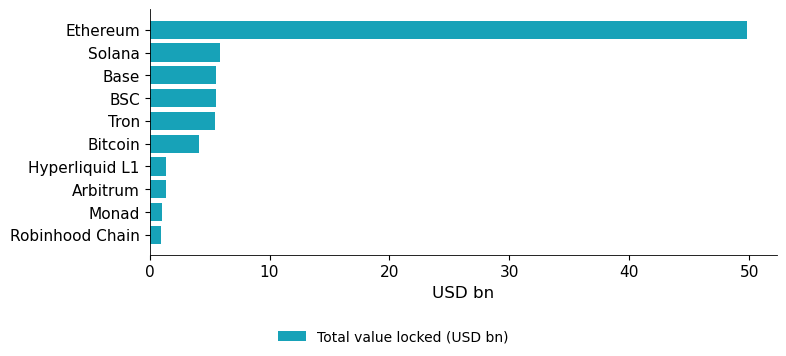

                 TVL (USD bn)  share of total TVL (%)
Ethereum                 49.8                    56.5
Solana                    5.9                     6.7
Base                      5.6                     6.3
BSC                       5.6                     6.3
Tron                      5.4                     6.1
Bitcoin                   4.1                     4.7
Hyperliquid L1            1.4                     1.6
Arbitrum                  1.4                     1.6
Monad                     1.0                     1.2
Robinhood Chain           1.0                     1.1
Total TVL, all chains: 88.1 USD bn


In [32]:
chains_now = pd.Series({x['name']: (x.get('tvl') or 0) / 1e9 for x in DF['https://api.llama.fi/v2/chains']})
cand = chains_now.sort_values(ascending=False).head(15).index
ch = pd.Series({c: llama_series('https://api.llama.fi/v2/historicalChainTvl/' + urllib.parse.quote(c)).loc[:END].iloc[-1]
                for c in cand}).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ch.index[::-1], ch.values[::-1], color=TEAL, label='Total value locked (USD bn)')
ax.set_xlabel('USD bn')
below(fig, ncol=1, bottom=0.10)
save_fig(fig, 'ch16_tvl_chains')
print((ch.rename('TVL (USD bn)').to_frame().assign(**{'share of total TVL (%)': 100 * ch / tvl.iloc[-1]})).round(1).to_string())
print(f'Total TVL, all chains: {tvl.iloc[-1]:.1f} USD bn')

### A.11 The growth rate of Bitcoin usage: CAGR

The **compound annual growth rate** between two dates $T$ years apart is

$$g = \left(\frac{X_{\text{end}}}{X_{\text{start}}}\right)^{1/T} - 1.$$

The slide uses monthly means of January 2015 and September 2025 ($T = 10.67$ years). Unlike the trend regression of
Section 5.2, the result depends on the two dates chosen.

In [33]:
Tyrs = 10 + 8 / 12
for lab, s in [('transactions per day', tx['BTC']), ('market value (USD bn)', mc['BTC'] / 1e9)]:
    x0, x1 = s.loc['2015-01'].mean(), s.loc['2025-09'].mean()
    print(f'Bitcoin {lab}: January 2015 {x0:,.1f}, September 2025 {x1:,.1f}, ratio {x1 / x0:.2f}, '
          f'CAGR {100 * ((x1 / x0) ** (1 / Tyrs) - 1):.1f}% a year')

Bitcoin transactions per day: January 2015 93,111.6, September 2025 506,379.0, ratio 5.44, CAGR 17.2% a year
Bitcoin market value (USD bn): January 2015 3.4, September 2025 2,250.6, ratio 658.97, CAGR 83.8% a year
